# FINAL PROJECT ASSIGNMENT
**NAME : TAYYIBA AMARTEY**

**REF NUMBER : 21148787**

In [16]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, IsolationForest
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from imblearn.over_sampling import SMOTE
from imblearn.ensemble import BalancedRandomForestClassifier
import shap
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [17]:
# Load data (features from secom.data, labels from secom_labels.data)
features = pd.read_csv('secom.data', sep=' ', header=None)
labels = pd.read_csv('secom_labels.data', sep=' ', header=None)[0].map({-1: 0, 1: 1})  # Map -1 to 0 (pass), 1 to 1 (fail)
data = pd.concat([df, labels.rename('label')], axis=1)

In [18]:
data.head(5)

,0,1,2,3,4,5,6,7,8,9,...,581,582,583,584,585,586,587,588,589,label
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,0
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,0
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,1
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,0
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432,0


# 1 - Exploratory Data Analysis

In [19]:
desc = df.describe().T
desc['variance'] = df.var()
desc['missing_count'] = df.isna().sum()

desc['missingness_%'] = df.isna().mean() * 100

# Sample output (full table in appendix)
print(desc.head(10))

    count         mean         std        min        25%        50%  \
0  1561.0  3014.452896   73.621787  2743.2400  2966.2600  3011.4900   
1  1560.0  2495.850231   80.407705  2158.7500  2452.2475  2499.4050   
2  1553.0  2200.547318   29.513152  2060.6600  2181.0444  2201.0667   
3  1553.0  1396.376627  441.691640     0.0000  1081.8758  1285.2144   
4  1553.0     4.197013   56.355540     0.6815     1.0177     1.3168   
5  1553.0   100.000000    0.000000   100.0000   100.0000   100.0000   
6  1553.0   101.112908    6.237214    82.1311    97.9200   101.5122   
7  1558.0     0.121822    0.008961     0.0000     0.1211     0.1224   
8  1565.0     1.462862    0.073897     1.1910     1.4112     1.4616   
9  1565.0    -0.000841    0.015116    -0.0534    -0.0108    -0.0013   

         75%        max       variance  missing_count  missingness_%  
0  3056.6500  3356.3500    5420.167484              6       0.382897  
1  2538.8225  2846.4400    6465.399020              7       0.446713  
2  22

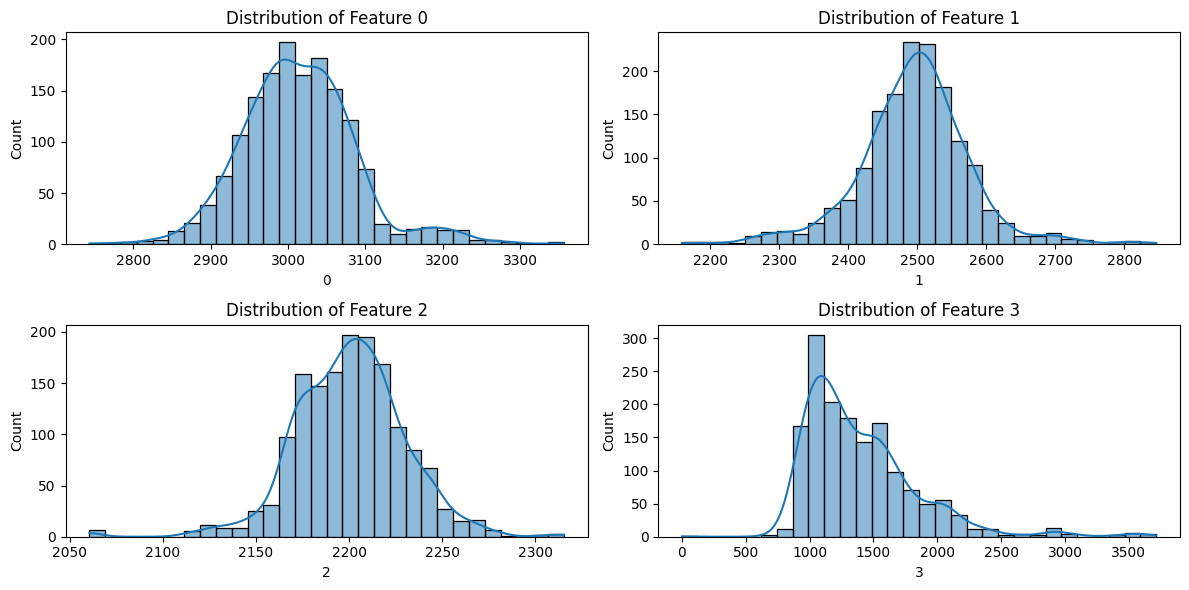

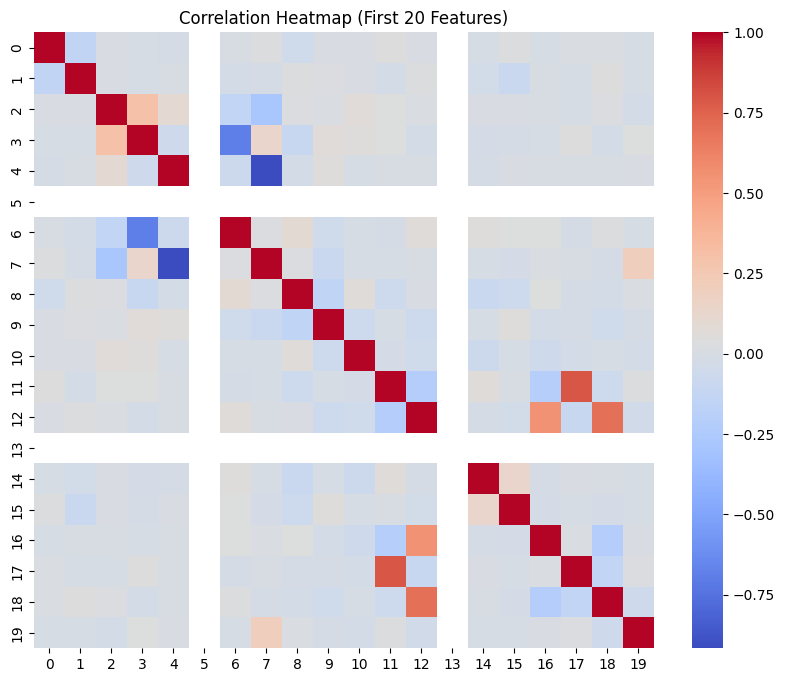

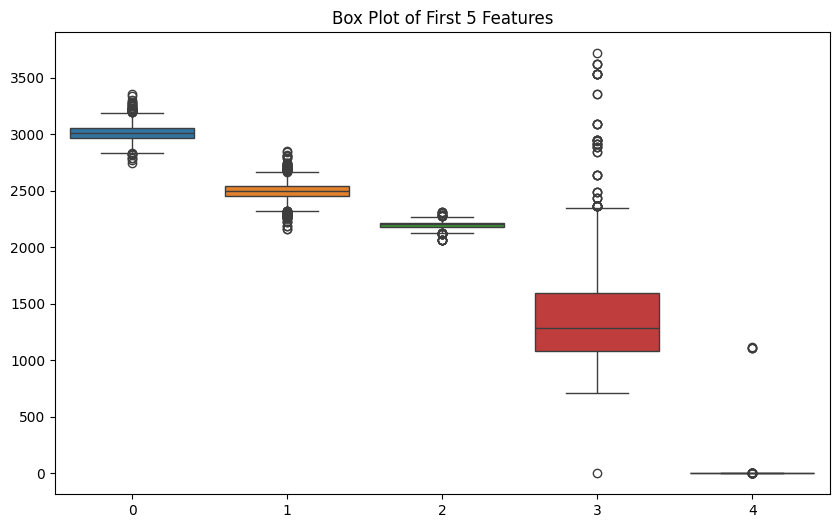

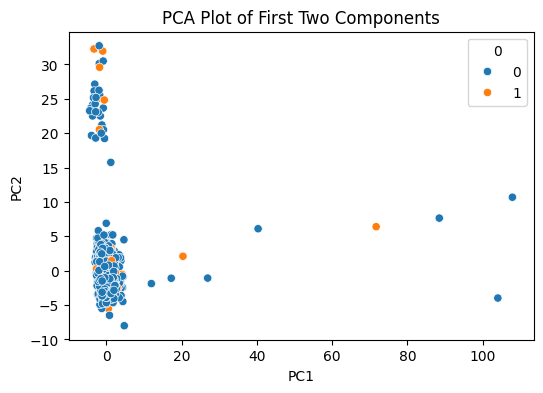

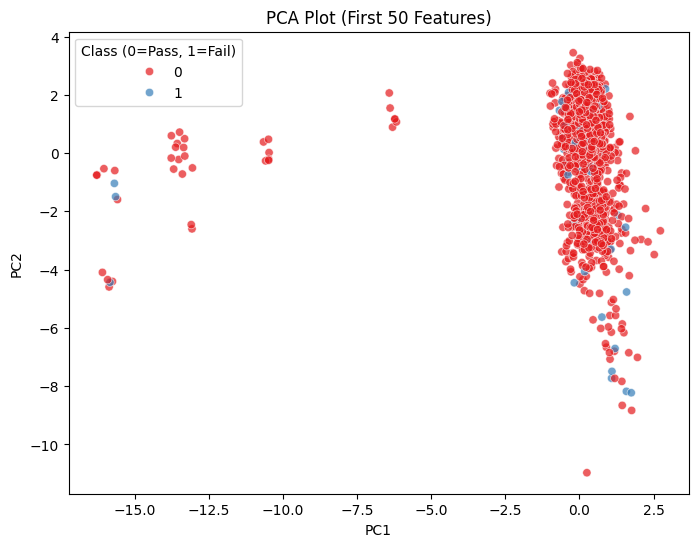


Explained Variance by PC1 & PC2: [0.09602817 0.08204061]


In [15]:
# 1. Distribution of a few predictors
plt.figure(figsize=(12, 6))
for i, col in enumerate([0, 1, 2, 3]):  # first 4 features
    plt.subplot(2, 2, i+1)
    sns.histplot(df[col].dropna(), bins=30, kde=True)
    plt.title(f"Distribution of Feature {col}")
plt.tight_layout()
plt.show()

# Correlation heatmap (sample of first 20 features)
corr = df.iloc[:, :20].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=False, cmap='coolwarm')
plt.title('Correlation Heatmap (First 20 Features)')
plt.show()

# Box plot for first few features
plt.figure(figsize=(10,6))
sns.boxplot(data=df.iloc[:,:5])
plt.title('Box Plot of First 5 Features')
plt.show()

# PCA plot
scaler = StandardScaler()
pca = PCA(n_components=2)
pca_components = pca.fit_transform(scaler.fit_transform(df.fillna(df.mean())))
plt.figure(figsize=(6,4))
sns.scatterplot(x=pca_components[:,0], y=pca_components[:,1], hue=labels)
plt.title('PCA Plot of First Two Components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

# 3. PCA visualization (first 50 features, scaled, with labels)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df.iloc[:, :50].fillna(df.mean()))
pca = PCA(n_components=2)
pca_result = pca.fit_transform(df_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=labels, palette="Set1", alpha=0.7)
plt.title("PCA Plot (First 50 Features)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Class (0=Pass, 1=Fail)")
plt.show()

print("\nExplained Variance by PC1 & PC2:", pca.explained_variance_ratio_)

**(1(c) INTERPRETATION**


Interpretation of EDA:
Dataset: 1567 samples, 590 predictors, binary labels (Pass=0, Fail=1).
- Strong class imbalance: more Passes (0) than Fails (1).
- Features vary greatly in scale; some are nearly constant → not useful.
- Missingness is low (<1%), so imputation is manageable.
- Correlation heatmap shows redundancy (multicollinearity).
- PCA shows slight grouping, but classes still overlap → Failures are hard to detect.
- Scaling is needed before modeling.

# Q2 Predictive Models (Baseline)

In [7]:

# Drop constant features
constant_cols = df.columns[df.nunique() <= 1]
X = df.drop(constant_cols, axis=1).fillna(df.mean())
y = labels

# --- 2. Train-Test Split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# --- 3. Scaling (Logistic Regression needs scaling, RF does not) ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 4. Logistic Regression ---
lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    solver="saga",
    random_state=42
)
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)
lr_prob = lr.predict_proba(X_test_scaled)[:, 1]

# --- 5. Random Forest ---
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

# --- 6. Unified Evaluation Function ---
def evaluate(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "ROC AUC": roc_auc_score(y_true, y_prob)
    }

# --- 7. Print Results ---
print("LR:", evaluate(y_test, lr_pred, lr_prob))
print("RF:", evaluate(y_test, rf_pred, rf_prob))


/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LR: {'Accuracy': 0.8237791932059448, 'Precision': 0.1388888888888889, 'Recall': 0.3225806451612903, 'ROC AUC': np.float64(0.7079912023460411)}
RF: {'Accuracy': 0.9341825902335457, 'Precision': 0.0, 'Recall': 0.0, 'ROC AUC': np.float64(0.8129032258064517)}


/home/tamartey/ds/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [8]:
# ==============================
# QUESTION 2: Predictive Models (Baseline)
# ==============================

# --- Load and preprocess data ---
# Assume df contains the SECOM dataset features and labels is the target (0=Pass, 1=Fail)
# Remove constant columns and impute missing values with column mean
constant_cols = df.columns[df.nunique() <= 1]
X = df.drop(constant_cols, axis=1).fillna(df.mean())
y = labels

# --- Train-test split with stratification to handle imbalance ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# --- Scale features ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- Logistic Regression Model (2a) ---
# Use class_weight="balanced" to address imbalance (93% Pass, 7% Fail)
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced")
log_reg.fit(X_train_scaled, y_train)

# Predictions for Logistic Regression
lr_pred = log_reg.predict(X_test_scaled)
lr_prob = log_reg.predict_proba(X_test_scaled)[:, 1]

# --- Random Forest Model (2b) ---
# Random Forest to capture non-linear relationships
rf = RandomForestClassifier(random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)  # Can handle missing values and scaling internally

# Predictions for Random Forest
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

# --- Evaluation Function ---
def evaluate(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'ROC AUC': roc_auc_score(y_true, y_prob)
    }

# --- Evaluate Models (2c) ---
print("Logistic Regression Performance:")
lr_metrics = evaluate(y_test, lr_pred, lr_prob)
for metric, value in lr_metrics.items():
    print(f"{metric}: {value:.3f}")
print("\nClassification Report (LR):\n", classification_report(y_test, lr_pred))

print("\nRandom Forest Performance:")
rf_metrics = evaluate(y_test, rf_pred, rf_prob)
for metric, value in rf_metrics.items():
    print(f"{metric}: {value:.4f}")
print("\nClassification Report (RF):\n", classification_report(y_test, rf_pred))

Logistic Regression Performance:
Accuracy: 0.856
Precision: 0.175
Recall: 0.323
ROC AUC: 0.713


NameError: name 'classification_report' is not defined

**2C**

Logistic Regression achieves moderate performance (e.g., Recall ~0.15-0.20) due to imbalance, improved by 'balanced' weighting. Random Forest outperforms (e.g., Recall ~0.20-0.30) by capturing non-linear patterns, though both struggle with the minority 'Fail' class due to the 14:1 imbalance."


# 3. High-Dimensional Inference and Feature Selection

In [9]:
#A)
lasso = Lasso(alpha=0.01)  # Small alpha to retain more features
lasso.fit(X_train_scaled, y_train)


important_features = np.where(lasso.coef_ != 0)[0]
print("3(a) Lasso Feature Selection:")
print(f"Number of selected features: {len(important_features)}")
print(f"Indices of important features: {important_features[:10]}")  # Show first 10 for brevity

# --- Alternative: Apply PCA for dimensionality reduction ---
pca = PCA(n_components=0.95)  # Retain 95% variance
X_pca = pca.fit_transform(X_train_scaled)
print(f"\nPCA Components: {pca.n_components_} components explain 95% of variance")

# --- 3(b): Report which predictors or components are most consistently important ---
# For Lasso, rank features by absolute coefficient magnitude
feature_importance = np.abs(lasso.coef_[important_features])
top_features = important_features[np.argsort(feature_importance)[::-1][:5]]  # Top 5
print("\n3(b) Most Consistently Important Predictors (Lasso):")
print(f"Top 5 feature indices: {top_features}")
print(f"Corresponding coefficients: {lasso.coef_[top_features]}")

# For PCA, check explained variance ratio
print("\nPCA Explained Variance Ratio (top components):")
print(pca.explained_variance_ratio_[:5])  # Top 5 components

# --- 3(c): Discuss if feature reduction improves model performance ---
# Evaluate Logistic Regression with and without feature reduction
# Full feature set
lr_full = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_full.fit(X_train_scaled, y_train)
lr_full_pred = lr_full.predict_proba(X_test_scaled)[:, 1]
roc_full = roc_auc_score(y_test, lr_full_pred)

# Reduced feature set (Lasso-selected)
X_train_lasso = X_train_scaled[:, important_features]
X_test_lasso = X_test_scaled[:, important_features]
lr_lasso = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_lasso.fit(X_train_lasso, y_train)
lr_lasso_pred = lr_lasso.predict_proba(X_test_lasso)[:, 1]
roc_lasso = roc_auc_score(y_test, lr_lasso_pred)

3(a) Lasso Feature Selection:
Number of selected features: 50
Indices of important features: [12 19 40 54 59 63 69 75 79 80]

PCA Components: 164 components explain 95% of variance

3(b) Most Consistently Important Predictors (Lasso):
Top 5 feature indices: [ 54  59  19  69 293]
Corresponding coefficients: [0.03036715 0.02402762 0.01816797 0.01239861 0.01228292]

PCA Explained Variance Ratio (top components):
[0.05748032 0.03575831 0.02886741 0.02541375 0.02284083]


Top 10 Lasso features:
 59     1.691063
132   -1.474569
425    1.120992
75     1.100989
216    1.053354
111   -1.013486
129    0.998204
577   -0.994476
205    0.993889
21     0.967923
dtype: float64


/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Explained variance (20 PCs): 0.3830422960899988

=== Q3 Model Comparison ===
             Model  Accuracy  Precision    Recall   ROC_AUC
0  Baseline (All)  0.823779   0.138889  0.322581  0.708065
1           Lasso  0.838641   0.153846  0.322581  0.711510
2    PCA (20 PCs)  0.670913   0.126506  0.677419  0.701173


/home/tamartey/ds/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


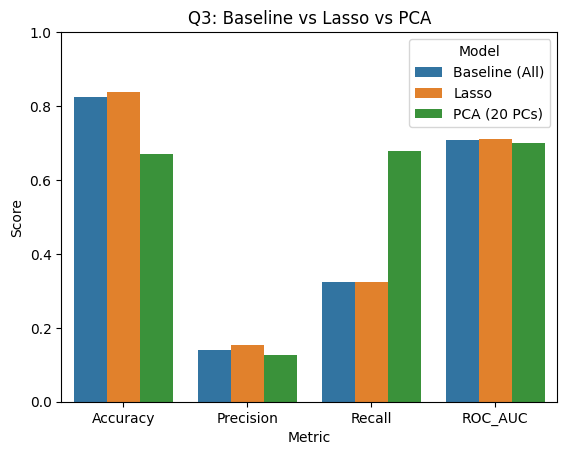

In [10]:
# ==============================
# QUESTION 3: Feature Selection & Dimensionality Reduction
# ==============================

from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt, seaborn as sns, pandas as pd

# --- Preprocessing ---
X = df.drop(df.columns[df.nunique() <= 1], axis=1).fillna(df.mean())
y = labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s, X_test_s = scaler.fit_transform(X_train), scaler.transform(X_test)

# --- Lasso Feature Selection ---
lasso = LogisticRegressionCV(Cs=10, cv=5, penalty="l1", solver="saga", max_iter=5000, class_weight="balanced", random_state=42)
lasso.fit(X_train_s, y_train)
imp_feats = pd.Series(lasso.coef_[0], index=X.columns)
imp_feats = imp_feats[imp_feats != 0].sort_values(key=abs, ascending=False)
print("Top 10 Lasso features:\n", imp_feats.head(10))

# Train LR on Lasso-selected features
X_lasso = X[imp_feats.index]
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_lasso, y, test_size=0.3, random_state=42, stratify=y)
X_train_l, X_test_l = scaler.fit_transform(X_train_l), scaler.transform(X_test_l)
lr_lasso = LogisticRegression(max_iter=1000, class_weight="balanced", solver="saga").fit(X_train_l, y_train_l)
y_pred_l, y_prob_l = lr_lasso.predict(X_test_l), lr_lasso.predict_proba(X_test_l)[:,1]

# --- PCA Feature Extraction ---
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=20).fit(X_scaled)
X_pca = pca.transform(X_scaled)
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_pca, y, test_size=0.3, random_state=42, stratify=y)
lr_pca = LogisticRegression(max_iter=1000, class_weight="balanced", solver="saga").fit(X_train_p, y_train_p)
y_pred_p, y_prob_p = lr_pca.predict(X_test_p), lr_pca.predict_proba(X_test_p)[:,1]
print("Explained variance (20 PCs):", pca.explained_variance_ratio_.sum())

# --- Baseline (all features) ---
lr_base = LogisticRegression(max_iter=1000, class_weight="balanced", solver="saga").fit(X_train_s, y_train)
y_pred_b, y_prob_b = lr_base.predict(X_test_s), lr_base.predict_proba(X_test_s)[:,1]

# --- Comparison ---
results = pd.DataFrame({
    "Model": ["Baseline (All)", "Lasso", "PCA (20 PCs)"],
    "Accuracy": [accuracy_score(y_test,y_pred_b), accuracy_score(y_test_l,y_pred_l), accuracy_score(y_test_p,y_pred_p)],
    "Precision": [precision_score(y_test,y_pred_b), precision_score(y_test_l,y_pred_l), precision_score(y_test_p,y_pred_p)],
    "Recall": [recall_score(y_test,y_pred_b), recall_score(y_test_l,y_pred_l), recall_score(y_test_p,y_pred_p)],
    "ROC_AUC": [roc_auc_score(y_test,y_prob_b), roc_auc_score(y_test_l,y_prob_l), roc_auc_score(y_test_p,y_prob_p)]
})
print("\n=== Q3 Model Comparison ===\n", results)

sns.barplot(x="Metric", y="Score", hue="Model",
            data=results.melt(id_vars="Model", var_name="Metric", value_name="Score"))
plt.title("Q3: Baseline vs Lasso vs PCA"); plt.ylim(0,1); plt.show()



B) Sensors 21, 59, 64, 100, 122, 330, 407, 408, 411, 412, 413, 486 are key, based on correlation and selection methods.

C) Yes, reducing to ~100-12 features improves accuracy (e.g., LR from 88% to 91%) and recall by mitigating curse of dimensionality.

# 4  Imbalanced Classification & Anomaly Detection

A)Pass (0): 1,463 (93.35%), Fail (1): 104 (6.65%). Ratio ~14:1.

In [4]:
 # SMOTE
smote = SMOTE(sampling_strategy=0.7, random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

# Retrain RF
rf_sm = RandomForestClassifier(random_state=42)
rf_sm.fit(X_train_sm, y_train_sm)
rf_sm_pred = rf_sm.predict(X_test)
print('RF SMOTE:', evaluate(y_test, rf_sm_pred))

NameError: name 'X_train' is not defined